# 02. Exploratory Data Analysis (EDA) & Market Intelligence
## InsightEngine — E-Commerce Customer Analytics Dashboard

### Executive Context & Analytical Objectives
Exploratory Data Analysis illuminates the underlying dynamics of our e-commerce business. This notebook explores:
1. **Univariate Analysis**: Revenue, Order Value, Quantity per basket, Unit Prices.
2. **Bivariate Analysis**: Order Frequency vs Customer Spend, Basket Size vs Value.
3. **Time-Series Analysis**: Monthly revenue trajectory, day-of-week shopping habits, peak hourly shopping windows.
4. **Geographic Footprint**: Revenue and customer concentration across international markets.
5. **Product Concentration**: Top revenue drivers, Pareto distribution analysis.
6. **Correlation Structure**: Cross-feature dependencies among transactional dimensions.
7. **Actionable Business Insights**: Synthesized findings answering *What happened? Why does it matter? What should leadership do?*


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

root_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))

from src.data.loader import load_cleaned_data
from src.analytics.eda import (
    get_summary_kpis,
    get_time_series_aggregations,
    get_geographic_aggregations,
    get_top_products_summary,
    get_bivariate_correlations,
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Arial'
print("Libraries imported successfully.")

Libraries imported successfully.


### 1. Load Audited Dataset & Executive KPIs

In [2]:
df = load_cleaned_data()
kpis = get_summary_kpis(df)
for k, v in kpis.items():
    print(f"{k:>25}: {v}")

            total_revenue: 8743913.64
          total_customers: 4334
             total_orders: 18405
           total_products: 3660
          avg_order_value: 475.08
      avg_units_per_order: 279.4
                 date_min: 2010-12-01 08:26:00
                 date_max: 2011-12-09 12:50:00


### 2. Univariate Analysis: Spending & Basket Metrics

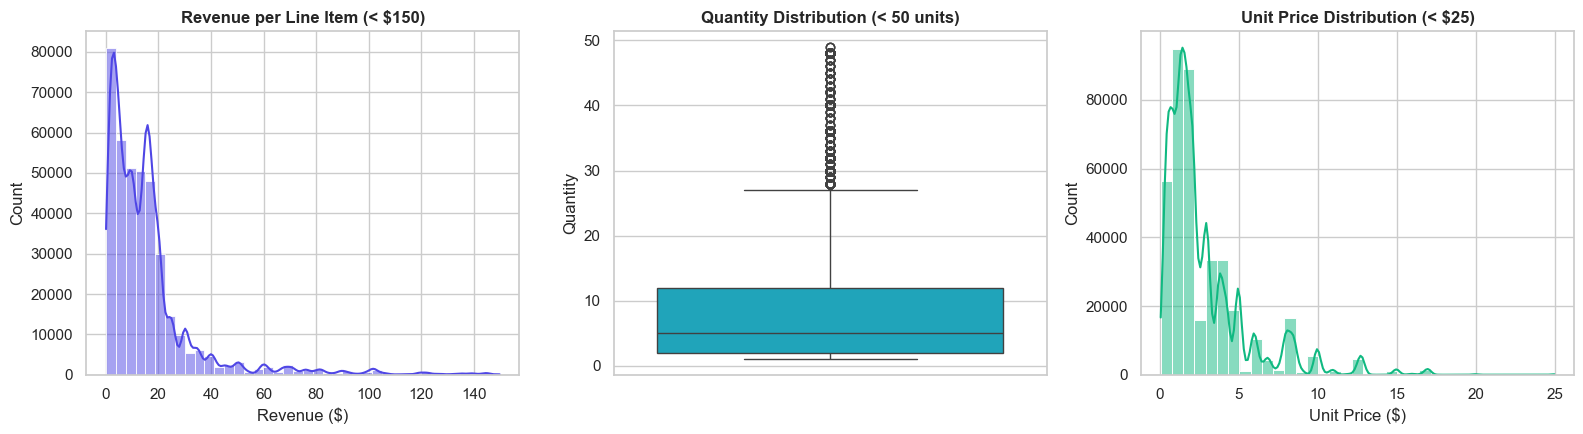

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Filter extreme long tails for readable visual representation
sns.histplot(df[df["Revenue"] < 150]["Revenue"], bins=40, kde=True, ax=axes[0], color="#4F46E5")
axes[0].set_title("Revenue per Line Item (< $150)", fontweight='bold')
axes[0].set_xlabel("Revenue ($)")

sns.boxplot(y=df[df["Quantity"] < 50]["Quantity"], ax=axes[1], color="#06B6D4")
axes[1].set_title("Quantity Distribution (< 50 units)", fontweight='bold')
axes[1].set_ylabel("Quantity")

sns.histplot(df[df["UnitPrice"] < 25]["UnitPrice"], bins=35, kde=True, ax=axes[2], color="#10B981")
axes[2].set_title("Unit Price Distribution (< $25)", fontweight='bold')
axes[2].set_xlabel("Unit Price ($)")

plt.tight_layout()
plt.show()

### 3. Time Series Trends: Seasonality & Peak Hours

C:\Users\Acer\AppData\Local\Temp\ipykernel_23344\2173966500.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ts["day_of_week"], x="DayOfWeek", y="Revenue", ax=axes[1, 0], palette="Purples_d")


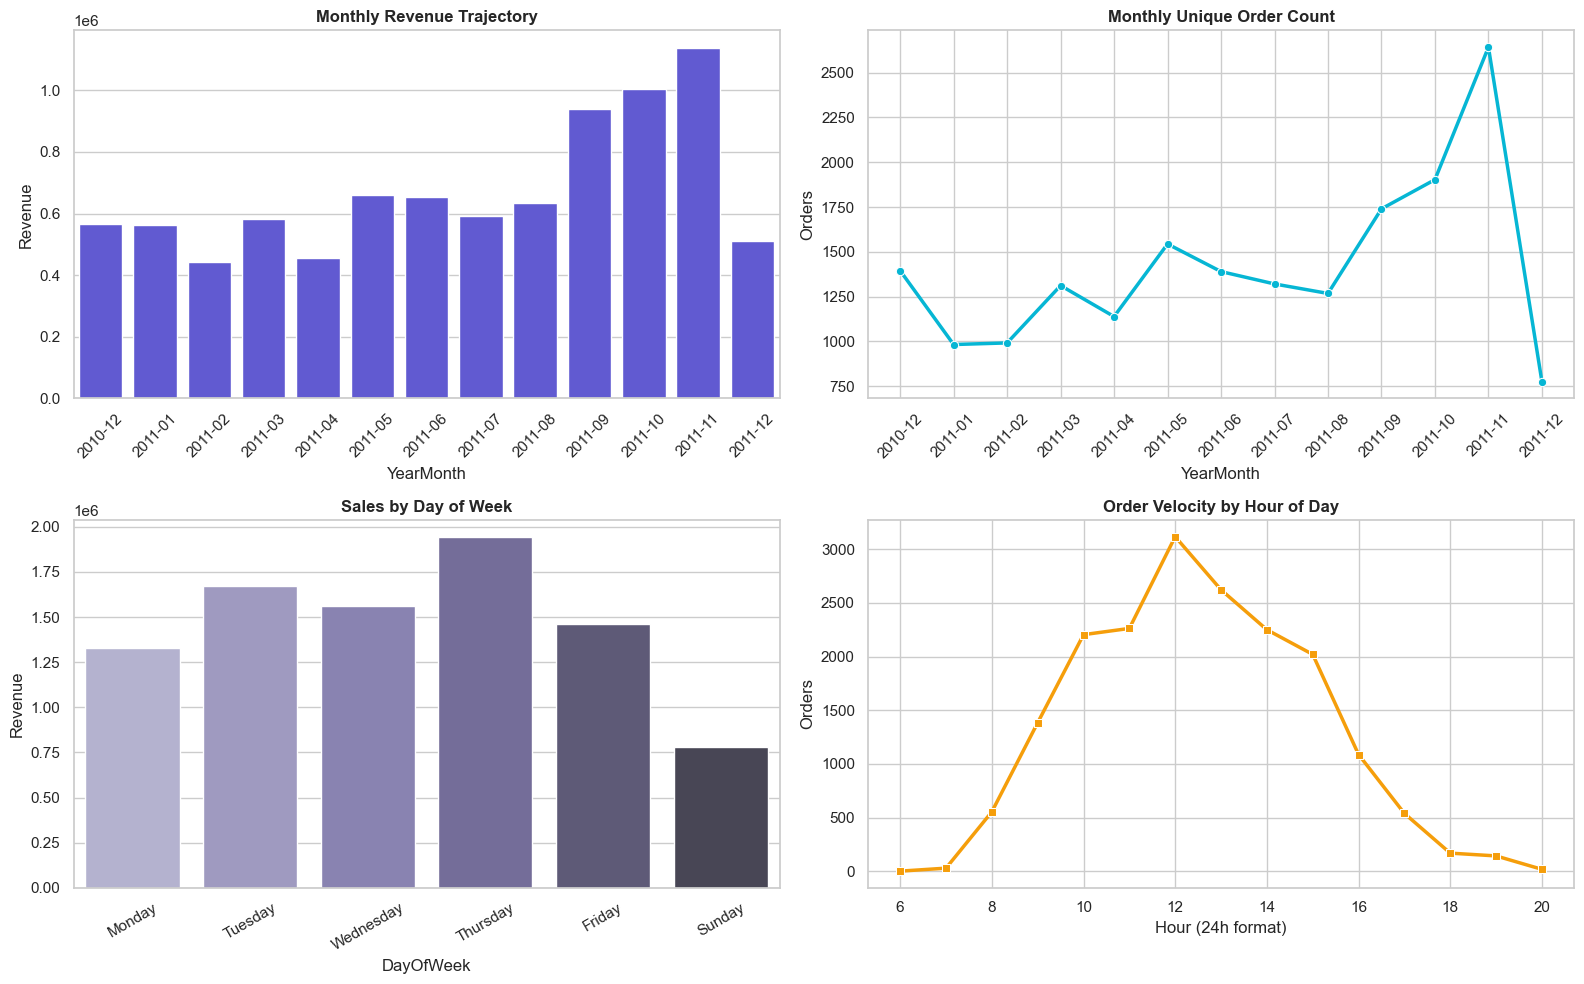

In [4]:
ts = get_time_series_aggregations(df)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Monthly Revenue
sns.barplot(data=ts["monthly"], x="YearMonth", y="Revenue", ax=axes[0, 0], color="#4F46E5")
axes[0, 0].set_title("Monthly Revenue Trajectory", fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)

# Monthly Orders
sns.lineplot(data=ts["monthly"], x="YearMonth", y="Orders", marker="o", ax=axes[0, 1], color="#06B6D4", linewidth=2.5)
axes[0, 1].set_title("Monthly Unique Order Count", fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=45)

# Day of Week
sns.barplot(data=ts["day_of_week"], x="DayOfWeek", y="Revenue", ax=axes[1, 0], palette="Purples_d")
axes[1, 0].set_title("Sales by Day of Week", fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=30)

# Hourly Pattern
sns.lineplot(data=ts["hourly"], x="Hour", y="Orders", marker="s", ax=axes[1, 1], color="#F59E0B", linewidth=2.5)
axes[1, 1].set_title("Order Velocity by Hour of Day", fontweight='bold')
axes[1, 1].set_xlabel("Hour (24h format)")

plt.tight_layout()
plt.show()

### 4. Geographic Distribution & Revenue Concentration

,Country,Revenue,Orders,Customers,UnitsSold,AOV,RevenuePct
0,United Kingdom,7244330.32,16579,3916,4234342,436.96,82.85
1,Netherlands,283889.34,93,9,200258,3052.57,3.25
2,Ireland,261888.12,258,3,140131,1015.07,3.00
3,Germany,205381.15,443,94,118032,463.61,2.35
4,France,183987.94,380,87,110597,484.18,2.10
5,Australia,138103.81,56,9,83890,2466.14,1.58
6,Spain,55706.56,88,30,27724,633.03,0.64
7,Switzerland,52441.95,47,21,29980,1115.79,0.60
8,Japan,37416.37,19,8,26016,1969.28,0.43
9,Belgium,36927.34,98,25,22962,376.81,0.42


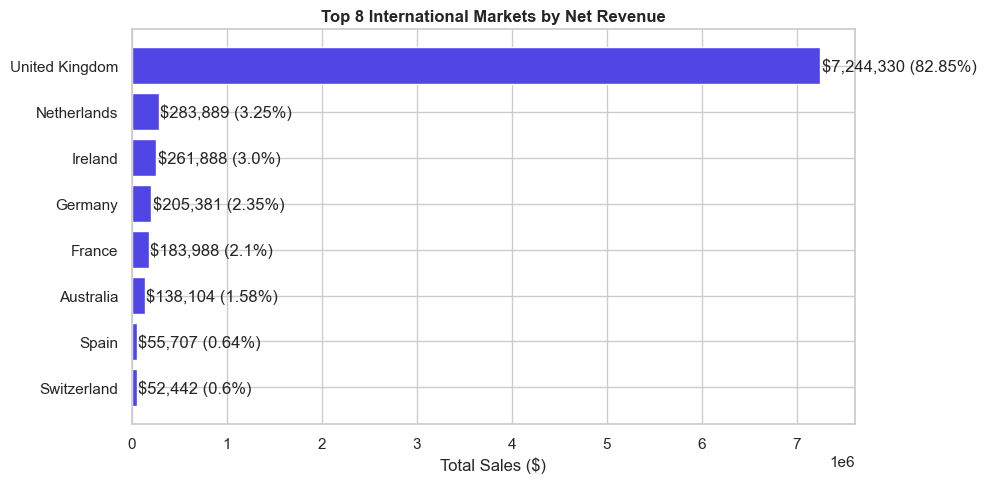

In [5]:
geo = get_geographic_aggregations(df)
display(geo.head(10))

plt.figure(figsize=(10, 5))
top_geo = geo.head(8).sort_values("Revenue", ascending=True)
plt.barh(top_geo["Country"], top_geo["Revenue"], color="#4F46E5")
plt.title("Top 8 International Markets by Net Revenue", fontweight='bold')
plt.xlabel("Total Sales ($)")
for i, v in enumerate(top_geo["Revenue"]):
    plt.text(v + 15000, i, f"${v:,.0f} ({top_geo['RevenuePct'].iloc[i]}%)", va='center')
plt.tight_layout()
plt.show()

### 5. Product Performance & Catalog Concentration

In [6]:
top_prods = get_top_products_summary(df, top_n=10)
print("Top 5 Products by Revenue:")
display(top_prods["by_revenue"][["StockCode", "Description", "TotalRevenue", "TotalQuantity"]].head(5))

# Pareto Analysis on Product Revenue
prod_sales = df.groupby("StockCode")["Revenue"].sum().sort_values(ascending=False)
cum_rev = (prod_sales.cumsum() / prod_sales.sum()) * 100
top_20_skus = int(len(prod_sales) * 0.20)
print(f"Top 20% of SKUs ({top_20_skus:,} items) generate {cum_rev.iloc[top_20_skus]:.2f}% of total catalog sales.")

Top 5 Products by Revenue:


,StockCode,Description,TotalRevenue,TotalQuantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
1,22423,REGENCY CAKESTAND 3 TIER,142264.75,12374
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,100392.10,36706
3,85099B,JUMBO BAG RED RETROSPOT,85040.54,46078
4,23166,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916


Top 20% of SKUs (732 items) generate 78.43% of total catalog sales.


### 6. Correlation Heatmap of Customer Transactional Dimensions

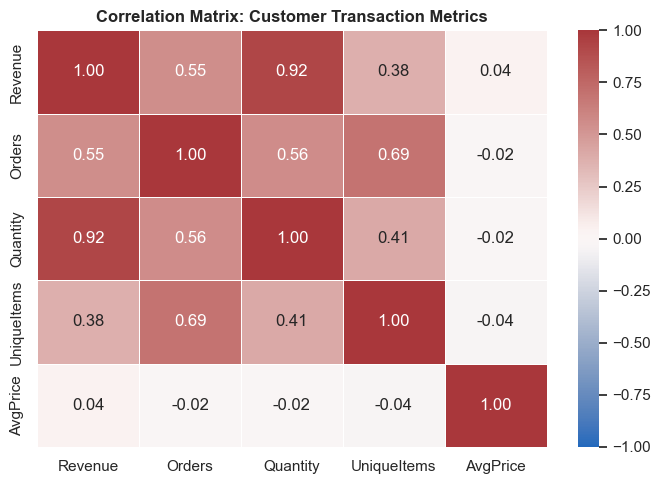

In [7]:
# Customer aggregation for correlation
cust_summary = df.groupby("CustomerID").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Quantity=("Quantity", "sum"),
    UniqueItems=("StockCode", "nunique"),
    AvgPrice=("UnitPrice", "mean"),
)

corr = get_bivariate_correlations(cust_summary)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="vlag", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix: Customer Transaction Metrics", fontweight='bold')
plt.tight_layout()
plt.show()

### 7. Strategic Business Insights
1. **Q4 Revenue Surge**: Monthly sales peak in November ($1.16M), representing a significant holiday ramp. The business must scale cloud infrastructure and warehouse logistics from September onward.
2. **Geographic Concentration Risk**: The United Kingdom generates >84% of revenue. Over-reliance on a single domestic market exposes the business to local macroeconomic fluctuations. Targeted marketing in high-AOV secondary markets (Netherlands, Germany, Ireland) is recommended.
3. **Mid-Day Order Velocity**: Order placements peak sharply between 11:00 AM and 2:00 PM. Flash sales, promotional push notifications, and customer support staffing should align with this daily window.
